# Theme Alpha Q4: Core/Satellite Portfolio

Q4 tests whether the expanded LowVolTrend sleeve is useful as a satellite around the original three-asset RiskParity core.

The core question:

> Can we improve return and risk-adjusted performance without turning the whole portfolio into a deep-drawdown theme bet?


In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/theme-alpha-q4-core-satellite")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2023-01-01"
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
INITIAL_NAV = 100.0
REBALANCE_DAYS = 10
REBALANCE_ANCHOR = "2024-01-02"

CSI300 = "510300.SS"
NASDAQ = "513100.SS"
NONFERROUS = "512400.SS"
CHIP = "159995.SZ"
COMM = "515880.SS"
GOLD = "518880.SS"
DIVIDEND = "510880.SS"
ENERGY = "159930.SZ"
BROKER = "512880.SS"
HK_TECH = "513180.SS"
HEALTHCARE = "512170.SS"

CORE_ASSETS = (CSI300, NASDAQ, GOLD)
ORIGINAL_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD)
EXPANDED_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD, DIVIDEND, ENERGY, BROKER, HK_TECH, HEALTHCARE)
ALL_SYMBOLS = tuple(dict.fromkeys(CORE_ASSETS + EXPANDED_THEME))
SYMBOL_NAMES = {
    CSI300: "沪深300ETF",
    NASDAQ: "纳指100ETF",
    NONFERROUS: "有色金属ETF",
    CHIP: "芯片ETF",
    COMM: "通信ETF",
    GOLD: "黄金ETF",
    DIVIDEND: "红利ETF",
    ENERGY: "能源ETF",
    BROKER: "证券ETF",
    HK_TECH: "恒生科技ETF",
    HEALTHCARE: "医疗ETF",
}

MA_WINDOW = 60
MOM_WINDOW = 63
VOL_WINDOW = 60
TOP_N = 3
RP_VOL_WINDOW = 20
CAP = 0.50
WINDOWS = {
    "2025_only": ("2025-01-01", "2025-12-31"),
    "2026_ytd": ("2026-01-01", None),
    "2025_to_date": ("2025-01-01", None),
}
print(f"Output dir: {OUTPUT_DIR}")


Output dir: outputs/theme-alpha-q4-core-satellite


## 1. Data Loading


In [2]:
def flatten_yfinance(df):
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df


def download_ohlc(symbol):
    df = yf.download(symbol, start=DATA_START, end=END, progress=False, auto_adjust=False, threads=False)
    df = flatten_yfinance(df)
    if df.empty:
        raise ValueError(f"No data for {symbol}")
    keep = [c for c in ["Open", "High", "Low", "Close", "Adj Close", "Volume"] if c in df.columns]
    df = df[keep].copy()
    df.columns = [c.lower().replace(" ", "_") for c in df.columns]
    df.index = pd.to_datetime(df.index).tz_localize(None)
    return df.sort_index()

market = {sym: download_ohlc(sym) for sym in ALL_SYMBOLS}
availability = pd.DataFrame([
    {"symbol": sym, "name": SYMBOL_NAMES[sym], "first_date": market[sym].index.min().date(), "last_date": market[sym].index.max().date(), "rows": len(market[sym])}
    for sym in ALL_SYMBOLS
])
availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(availability)

idx = None
for sym in ALL_SYMBOLS:
    cur = market[sym]["close"].dropna().index
    idx = cur if idx is None else idx.union(cur)
idx = pd.DatetimeIndex(idx).sort_values()
close = pd.DataFrame({sym: market[sym]["close"].reindex(idx) for sym in ALL_SYMBOLS}).ffill().dropna()
returns = close.pct_change().fillna(0.0)
print(f"Aligned sample: {close.index.min().date()} to {close.index.max().date()}, rows={len(close)}")


,symbol,name,first_date,last_date,rows
0,510300.SS,沪深300ETF,2023-01-03,2026-06-23,837
1,513100.SS,纳指100ETF,2023-01-03,2026-06-23,838
2,518880.SS,黄金ETF,2023-01-03,2026-06-23,837
3,512400.SS,有色金属ETF,2023-01-03,2026-06-23,837
4,159995.SZ,芯片ETF,2023-01-03,2026-06-23,837
5,515880.SS,通信ETF,2023-01-03,2026-06-23,837
6,510880.SS,红利ETF,2023-01-03,2026-06-23,837
7,159930.SZ,能源ETF,2023-01-03,2026-06-23,818
8,512880.SS,证券ETF,2023-01-03,2026-06-23,837
9,513180.SS,恒生科技ETF,2023-01-03,2026-06-23,837


Aligned sample: 2023-01-03 to 2026-06-23, rows=838


## 2. Strategy Helpers


In [3]:
def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def apply_cap(weights, universe, cap=None):
    if cap is None:
        return normalize_weights(weights, universe)
    s = pd.Series({sym: max(0.0, weights.get(sym, 0.0)) for sym in universe}, dtype=float)
    total = s.sum()
    if total <= 0:
        return normalize_weights({}, universe)
    s = s / total
    cap = float(cap)
    for _ in range(30):
        over = s > cap + 1e-12
        if not over.any():
            break
        excess = (s[over] - cap).sum()
        s[over] = cap
        under = s < cap - 1e-12
        capacity = (cap - s[under]).clip(lower=0.0)
        if excess <= 1e-12 or capacity.sum() <= 1e-12:
            break
        base = s[under].clip(lower=0.0)
        add = excess * (base / base.sum() if base.sum() > 1e-12 else capacity / capacity.sum())
        add = np.minimum(add, capacity)
        s.loc[add.index] += add
    return normalize_weights(s.to_dict(), universe)


def rebalance_dates(index):
    idx = pd.DatetimeIndex(index)
    start = idx.searchsorted(pd.Timestamp(REBALANCE_ANCHOR))
    return set(pd.DatetimeIndex(idx[start::REBALANCE_DAYS]))


def risk_parity_weight(date, eligible, universe, cap=None):
    eligible = [sym for sym in eligible if sym in universe]
    if not eligible:
        return normalize_weights({}, universe)
    loc = close.index.get_loc(date)
    if loc < RP_VOL_WINDOW:
        return normalize_weights({}, universe)
    hist = returns.iloc[loc - RP_VOL_WINDOW + 1:loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({}, universe)
    inv = 1.0 / vols
    raw = (inv / inv.sum()).to_dict()
    return apply_cap(raw, universe, cap)


def low_vol_trend_selector(universe):
    def select(date):
        loc = close.index.get_loc(date)
        warmup = max(MA_WINDOW, MOM_WINDOW, VOL_WINDOW)
        if loc < warmup:
            return []
        symbols = list(universe)
        price = close.iloc[loc][symbols]
        ma = close.iloc[loc - MA_WINDOW + 1:loc + 1][symbols].mean()
        mom = price / close.iloc[loc - MOM_WINDOW][symbols] - 1.0
        vols = returns.iloc[loc - VOL_WINDOW + 1:loc + 1][symbols].std(ddof=1)
        eligible = price.index[(price > ma) & (mom > 0)].tolist()
        if not eligible:
            return []
        return vols[eligible].sort_values().head(TOP_N).index.tolist()
    return select


def all_assets(universe):
    return lambda _date: list(universe)


def build_weights(universe, selector, allocator):
    rdates = rebalance_dates(close.index)
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in rdates:
            last = allocator(date, selector(date))
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def expand_weights(weights, all_assets):
    out = pd.DataFrame(0.0, index=weights.index, columns=list(all_assets) + ["CASH"])
    for col in weights.columns:
        if col in out.columns:
            out[col] = weights[col]
    return out


def combine_weights(name, sleeves):
    # sleeves: list of (allocation, weights_df)
    out = pd.DataFrame(0.0, index=close.index, columns=list(ALL_SYMBOLS) + ["CASH"])
    for allocation, weights in sleeves:
        ew = expand_weights(weights, ALL_SYMBOLS)
        out += allocation * ew.reindex(close.index).ffill().fillna(0.0)
    total = out[list(ALL_SYMBOLS)].sum(axis=1) + out["CASH"]
    out = out.div(total.replace(0, np.nan), axis=0).fillna(0.0)
    return out


def turnover_from_weights(signal_weights):
    actual = signal_weights[list(ALL_SYMBOLS) + ["CASH"]].shift(1).fillna(0.0)
    return 0.5 * actual.diff().abs().sum(axis=1).fillna(actual.abs().sum(axis=1))


def backtest_combined(name, signal_weights, cost_bps=0.0):
    asset_weights = signal_weights[list(ALL_SYMBOLS)].shift(1).fillna(0.0)
    gross = (asset_weights * returns[list(ALL_SYMBOLS)]).sum(axis=1)
    turnover = turnover_from_weights(signal_weights)
    net = gross - turnover * (cost_bps / 10000.0)
    nav = (1.0 + net).cumprod() * INITIAL_NAV
    return {"name": name, "weights": signal_weights, "returns": net, "gross_returns": gross, "turnover": turnover, "nav": nav.rename(name), "cost_bps": cost_bps}


def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


## 3. Build Core And Satellite Sleeves


In [4]:
core_w = build_weights(CORE_ASSETS, all_assets(CORE_ASSETS), lambda d, e: risk_parity_weight(d, e, CORE_ASSETS, None))
expanded_lvt_w = build_weights(EXPANDED_THEME, low_vol_trend_selector(EXPANDED_THEME), lambda d, e: risk_parity_weight(d, e, EXPANDED_THEME, CAP))
original_lvt_w = build_weights(ORIGINAL_THEME, low_vol_trend_selector(ORIGINAL_THEME), lambda d, e: risk_parity_weight(d, e, ORIGINAL_THEME, CAP))

portfolio_weights = {
    "Core_100": combine_weights("Core_100", [(1.0, core_w)]),
    "Core90_ExpandedLVT10": combine_weights("Core90_ExpandedLVT10", [(0.90, core_w), (0.10, expanded_lvt_w)]),
    "Core80_ExpandedLVT20": combine_weights("Core80_ExpandedLVT20", [(0.80, core_w), (0.20, expanded_lvt_w)]),
    "Core70_ExpandedLVT30": combine_weights("Core70_ExpandedLVT30", [(0.70, core_w), (0.30, expanded_lvt_w)]),
    "Core60_ExpandedLVT40": combine_weights("Core60_ExpandedLVT40", [(0.60, core_w), (0.40, expanded_lvt_w)]),
    "Core80_OriginalLVT20": combine_weights("Core80_OriginalLVT20", [(0.80, core_w), (0.20, original_lvt_w)]),
    "ExpandedLVT_100": combine_weights("ExpandedLVT_100", [(1.0, expanded_lvt_w)]),
    "OriginalLVT_100": combine_weights("OriginalLVT_100", [(1.0, original_lvt_w)]),
}

portfolios = {name: backtest_combined(name, weights, cost_bps=0.0) for name, weights in portfolio_weights.items()}
print("Portfolios:")
for name in portfolios:
    print(" -", name)


Portfolios:
 - Core_100
 - Core90_ExpandedLVT10
 - Core80_ExpandedLVT20
 - Core70_ExpandedLVT30
 - Core60_ExpandedLVT40
 - Core80_OriginalLVT20
 - ExpandedLVT_100
 - OriginalLVT_100


## 4. Metrics And Diagnostics


In [5]:
def slice_returns(port, start, end=None):
    r = port["returns"].loc[pd.Timestamp(start):]
    if end is not None:
        r = r.loc[:pd.Timestamp(end)]
    return r.dropna()


def metrics_row(name, r, weights=None, turnover=None):
    r = r.dropna()
    nav = nav_from_returns(r)
    total = nav.iloc[-1] / INITIAL_NAV - 1.0
    ann = (1.0 + total) ** (TRADING_DAYS / len(r)) - 1.0
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    dd = nav / nav.cummax() - 1.0
    mdd = dd.min()
    sharpe = ann / vol if vol > 0 else np.nan
    calmar = ann / abs(mdd) if mdd < 0 else np.nan
    monthly = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    row = {"策略": name, "累计收益": total, "年化收益": ann, "年化波动": vol, "最大回撤": mdd, "夏普": sharpe, "卡玛": calmar, "月胜率": (monthly > 0).mean(), "最好月份": monthly.max(), "最差月份": monthly.min()}
    if turnover is not None:
        t = turnover.reindex(r.index).fillna(0.0)
        row["年化换手"] = t.mean() * TRADING_DAYS
        row["总换手"] = t.sum()
    if weights is not None:
        w = weights.reindex(r.index).ffill().fillna(0.0)
        asset_cols = [c for c in w.columns if c != "CASH"]
        row["平均现金"] = w["CASH"].mean()
        row["平均最大单资产权重"] = w[asset_cols].max(axis=1).mean()
        row["当前最大单资产权重"] = w[asset_cols].iloc[-1].max()
    return row


def monthly_diagnostics(name, r):
    m = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0).dropna()
    wins = m[m > 0]
    losses = m[m < 0]
    return {"策略": name, "月数": len(m), "月胜率": (m > 0).mean(), "平均盈利月": wins.mean() if len(wins) else np.nan, "平均亏损月": losses.mean() if len(losses) else np.nan, "最差月": m.min(), "最好月": m.max(), "盈利因子": wins.sum() / abs(losses.sum()) if len(losses) and losses.sum() != 0 else np.nan}


def drawdown_events(nav):
    dd = nav / nav.cummax() - 1.0
    events = []
    in_dd = False
    start = trough = peak = None
    trough_depth = 0.0
    for date, depth in dd.items():
        if depth < 0 and not in_dd:
            in_dd = True
            start = date
            peak = nav.loc[:date].idxmax()
            trough = date
            trough_depth = depth
        elif depth < 0 and in_dd:
            if depth < trough_depth:
                trough = date
                trough_depth = depth
        elif depth >= 0 and in_dd:
            events.append({"peak_date": peak, "start_date": start, "trough_date": trough, "recovery_date": date, "depth": trough_depth, "recovery_days": (date - start).days, "recovered": True})
            in_dd = False
    if in_dd:
        last = dd.index[-1]
        events.append({"peak_date": peak, "start_date": start, "trough_date": trough, "recovery_date": pd.NaT, "depth": trough_depth, "recovery_days": np.nan, "unrecovered_days": (last - start).days, "recovered": False})
    return pd.DataFrame(events)


def underwater_recovery(name, r):
    nav = nav_from_returns(r)
    dd = nav / nav.cummax() - 1.0
    events = drawdown_events(nav)
    recovered = events[events["recovered"]] if len(events) else pd.DataFrame()
    unresolved = events[~events["recovered"]] if len(events) else pd.DataFrame()
    return {"策略": name, "水下时间占比": (dd < 0).mean(), "平均水下": dd[dd < 0].mean() if (dd < 0).any() else 0.0, "最长水下天数": events["recovery_days"].fillna(events.get("unrecovered_days", np.nan)).max() if len(events) else 0, "超过-10%天数": int((dd <= -0.10).sum()), "平均修复天数": recovered["recovery_days"].mean() if len(recovered) else np.nan, "最长修复天数": recovered["recovery_days"].max() if len(recovered) else np.nan, "未修复回撤": unresolved["depth"].iloc[-1] if len(unresolved) else 0.0, "未修复天数": unresolved["unrecovered_days"].iloc[-1] if len(unresolved) and "unrecovered_days" in unresolved else 0, "回撤事件数": len(events)}


def evaluate(portfolios, window_name, start, end=None):
    summary_rows = []
    monthly_rows = []
    underwater_rows = []
    navs = {}
    for name, port in portfolios.items():
        r = slice_returns(port, start, end)
        if len(r) < 20:
            continue
        summary_rows.append(metrics_row(name, r, port["weights"], port["turnover"]))
        monthly_rows.append(monthly_diagnostics(name, r))
        underwater_rows.append(underwater_recovery(name, r))
        navs[name] = nav_from_returns(r)
    summary = pd.DataFrame(summary_rows).set_index("策略").sort_values("夏普", ascending=False)
    monthly = pd.DataFrame(monthly_rows).set_index("策略").reindex(summary.index)
    underwater = pd.DataFrame(underwater_rows).set_index("策略").reindex(summary.index)
    summary.to_csv(OUTPUT_DIR / f"summary_{window_name}.csv", encoding="utf-8-sig")
    monthly.to_csv(OUTPUT_DIR / f"monthly_diagnostics_{window_name}.csv", encoding="utf-8-sig")
    underwater.to_csv(OUTPUT_DIR / f"underwater_recovery_{window_name}.csv", encoding="utf-8-sig")
    pd.DataFrame(navs).to_csv(OUTPUT_DIR / f"nav_{window_name}.csv", encoding="utf-8-sig")
    pd.DataFrame(navs).apply(lambda s: s / s.cummax() - 1.0).to_csv(OUTPUT_DIR / f"underwater_{window_name}.csv", encoding="utf-8-sig")
    return summary, monthly, underwater, pd.DataFrame(navs)

summary_tables = {}
monthly_tables = {}
underwater_tables = {}
nav_tables = {}
for window_name, (start, end) in WINDOWS.items():
    summary, monthly, underwater, navs = evaluate(portfolios, window_name, start, end)
    summary_tables[window_name] = summary
    monthly_tables[window_name] = monthly
    underwater_tables[window_name] = underwater
    nav_tables[window_name] = navs
    print() ; print(f"Summary - {window_name}")
    display(summary[["累计收益", "年化收益", "最大回撤", "夏普", "卡玛", "年化换手", "平均最大单资产权重"]].round(4))
    display(monthly.round(4))
    display(underwater.round(4))



Summary - 2025_only


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均最大单资产权重
策略,,,,,,,
OriginalLVT_100,0.6870,0.7200,-0.0731,4.1569,9.8507,5.4811,0.4666
Core80_OriginalLVT20,0.4269,0.4458,-0.0667,3.2206,6.6820,2.7607,0.4111
Core60_ExpandedLVT40,0.3792,0.3957,-0.0642,2.9614,6.1623,4.2940,0.3800
Core70_ExpandedLVT30,0.3764,0.3928,-0.0646,2.9596,6.0796,3.7630,0.3905
Core80_ExpandedLVT20,0.3735,0.3898,-0.0650,2.9467,5.9960,3.2632,0.4020
Core90_ExpandedLVT10,0.3706,0.3867,-0.0654,2.9226,5.9115,2.8049,0.4217
Core_100,0.3676,0.3835,-0.0658,2.8877,5.8261,2.3630,0.4456
ExpandedLVT_100,0.3944,0.4116,-0.0778,2.7787,5.2914,7.5672,0.4580


,月数,月胜率,平均盈利月,平均亏损月,最差月,最好月,盈利因子
策略,,,,,,,
OriginalLVT_100,12,0.8333,0.0552,-0.0036,-0.0041,0.1247,77.1530
Core80_OriginalLVT20,12,0.9167,0.0339,-0.0077,-0.0077,0.0883,48.3514
Core60_ExpandedLVT40,12,0.9167,0.0303,-0.0037,-0.0037,0.0874,89.5614
Core70_ExpandedLVT30,12,0.9167,0.0302,-0.0050,-0.0050,0.0868,66.3827
Core80_ExpandedLVT20,12,0.9167,0.0301,-0.0063,-0.0063,0.0863,52.6008
Core90_ExpandedLVT10,12,0.9167,0.0300,-0.0076,-0.0076,0.0857,43.4655
Core_100,12,0.9167,0.0300,-0.0089,-0.0089,0.0852,36.9664
ExpandedLVT_100,12,0.8333,0.0351,-0.0037,-0.0062,0.0906,47.4050


,水下时间占比,平均水下,最长水下天数,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,未修复天数,回撤事件数
策略,,,,,,,,,
OriginalLVT_100,0.6749,-0.0161,50.0,0,7.2727,50.0,-0.0246,6.0,34
Core80_OriginalLVT20,0.6543,-0.0139,55.0,0,8.8519,55.0,-0.0184,2.0,28
Core60_ExpandedLVT40,0.6996,-0.0127,70.0,0,10.0800,70.0,-0.0189,6.0,26
Core70_ExpandedLVT30,0.6790,-0.0129,69.0,0,9.5000,69.0,-0.0186,2.0,27
Core80_ExpandedLVT20,0.6667,-0.0130,69.0,0,9.0370,69.0,-0.0184,2.0,28
Core90_ExpandedLVT10,0.6584,-0.0133,55.0,0,8.5714,55.0,-0.0182,2.0,29
Core_100,0.6749,-0.0136,55.0,0,9.3846,55.0,-0.0181,2.0,27
ExpandedLVT_100,0.7572,-0.0160,78.0,0,9.1154,78.0,-0.0395,47.0,27



Summary - 2026_ytd


...

,水下时间占比,平均水下,最长水下天数,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,未修复天数,回撤事件数
策略,,,,,,,,,
ExpandedLVT_100,0.8378,-0.0504,82.0,1,24.0000,82.0,-0.0311,0.0,7
Core60_ExpandedLVT40,0.8739,-0.0367,115.0,1,30.6000,115.0,-0.0289,0.0,6
OriginalLVT_100,0.8559,-0.1405,144.0,66,1.0000,1.0,-0.2545,144.0,4
Core70_ExpandedLVT30,0.8739,-0.0376,115.0,1,33.2500,115.0,-0.0598,20.0,5
Core80_ExpandedLVT20,0.8739,-0.0386,115.0,3,33.2500,115.0,-0.0631,20.0,5
Core80_OriginalLVT20,0.8829,-0.0569,144.0,13,2.6667,5.0,-0.1541,144.0,4
Core90_ExpandedLVT10,0.8649,-0.0405,101.0,6,22.0000,101.0,-0.0665,20.0,7
Core_100,0.8649,-0.0421,101.0,6,22.0000,101.0,-0.0699,20.0,7



Summary - 2025_to_date


,累计收益,年化收益,最大回撤,夏普,卡玛,年化换手,平均最大单资产权重
策略,,,,,,,
OriginalLVT_100,0.9454,0.6060,-0.2545,2.5549,2.3814,6.4118,0.4409
ExpandedLVT_100,0.6447,0.4250,-0.1077,2.3098,3.9447,8.4467,0.4596
Core60_ExpandedLVT40,0.5114,0.3418,-0.1104,2.2029,3.0951,4.4735,0.3511
Core70_ExpandedLVT30,0.4887,0.3275,-0.1147,2.1188,2.8549,3.8272,0.3676
Core80_OriginalLVT20,0.5159,0.3447,-0.1541,2.0307,2.2361,2.7078,0.3928
Core80_ExpandedLVT20,0.4660,0.3130,-0.1190,2.0160,2.6301,3.2051,0.3865
Core90_ExpandedLVT10,0.4432,0.2985,-0.1234,1.8974,2.4194,2.6422,0.4130
Core_100,0.4204,0.2838,-0.1277,1.7673,2.2217,2.1175,0.4432


,月数,月胜率,平均盈利月,平均亏损月,最差月,最好月,盈利因子
策略,,,,,,,
OriginalLVT_100,18,0.7778,0.0641,-0.0437,-0.1666,0.1456,5.1362
ExpandedLVT_100,18,0.7778,0.0413,-0.0150,-0.0521,0.1172,9.6631
Core60_ExpandedLVT40,18,0.7778,0.0375,-0.0237,-0.0653,0.0874,5.5336
Core70_ExpandedLVT30,18,0.7778,0.0371,-0.0263,-0.0677,0.0868,4.9486
Core80_OriginalLVT20,18,0.7778,0.0406,-0.0329,-0.0938,0.0883,4.3134
Core80_ExpandedLVT20,18,0.7778,0.0367,-0.0288,-0.0701,0.0863,4.4634
Core90_ExpandedLVT10,18,0.7778,0.0364,-0.0314,-0.0725,0.0873,4.0544
Core_100,18,0.7778,0.0360,-0.0340,-0.0749,0.0922,3.7051


,水下时间占比,平均水下,最长水下天数,超过-10%天数,平均修复天数,最长修复天数,未修复回撤,未修复天数,回撤事件数
策略,,,,,,,,,
OriginalLVT_100,0.7345,-0.0615,144.0,66,6.8919,50.0,-0.2545,144.0,38
ExpandedLVT_100,0.7881,-0.0274,82.0,1,13.1818,82.0,-0.0311,0.0,34
Core60_ExpandedLVT40,0.7542,-0.0214,115.0,1,13.4194,115.0,-0.0289,0.0,32
Core70_ExpandedLVT30,0.7401,-0.0220,115.0,1,12.4839,115.0,-0.0598,20.0,32
Core80_OriginalLVT20,0.7260,-0.0303,144.0,13,8.1935,55.0,-0.1541,144.0,32
Core80_ExpandedLVT20,0.7316,-0.0226,115.0,3,12.0000,115.0,-0.0631,20.0,33
Core90_ExpandedLVT10,0.7232,-0.0235,101.0,6,10.8286,101.0,-0.0665,20.0,36
Core_100,0.7373,-0.0240,101.0,6,11.6364,101.0,-0.0699,20.0,34


## 5. Cost Sensitivity And Weights


In [6]:
def recost_portfolios(cost_bps):
    return {name: backtest_combined(name, weights, cost_bps=cost_bps) for name, weights in portfolio_weights.items()}

cost_rows = []
for cost in [0, 10, 20]:
    cost_ports = recost_portfolios(cost)
    for name, port in cost_ports.items():
        r = slice_returns(port, "2025-01-01")
        row = metrics_row(name, r, port["weights"], port["turnover"])
        row["成本bps"] = cost
        cost_rows.append(row)
cost_sensitivity = pd.DataFrame(cost_rows).set_index(["成本bps", "策略"]).sort_index()
cost_sensitivity.to_csv(OUTPUT_DIR / "cost_sensitivity_2025_to_date.csv", encoding="utf-8-sig")
display(cost_sensitivity[["累计收益", "最大回撤", "夏普", "卡玛", "年化换手"]].round(4))

latest = []
avg = []
for name, port in portfolios.items():
    w = port["weights"].loc["2025-01-01":]
    asset_cols = [c for c in w.columns if c != "CASH"]
    latest.append({"策略": name, **{SYMBOL_NAMES.get(c, c): w[c].iloc[-1] for c in asset_cols}, "现金": w["CASH"].iloc[-1]})
    avg.append({"策略": name, **{SYMBOL_NAMES.get(c, c): w[c].mean() for c in asset_cols}, "现金": w["CASH"].mean()})
latest_weights = pd.DataFrame(latest).set_index("策略")
average_weights = pd.DataFrame(avg).set_index("策略")
latest_weights.to_csv(OUTPUT_DIR / "latest_weights_2025_to_date.csv", encoding="utf-8-sig")
average_weights.to_csv(OUTPUT_DIR / "average_weights_2025_to_date.csv", encoding="utf-8-sig")
display(latest_weights.round(4))


累计收益    最大回撤      夏普      卡玛    年化换手
成本bps 策略                                                          
0     Core60_ExpandedLVT40  0.5114 -0.1104  2.2029  3.0951  4.4735
      Core70_ExpandedLVT30  0.4887 -0.1147  2.1188  2.8549  3.8272
      Core80_ExpandedLVT20  0.4660 -0.1190  2.0160  2.6301  3.2051
      Core80_OriginalLVT20  0.5159 -0.1541  2.0307  2.2361  2.7078
      Core90_ExpandedLVT10  0.4432 -0.1234  1.8974  2.4194  2.6422
      Core_100              0.4204 -0.1277  1.7673  2.2217  2.1175
      ExpandedLVT_100       0.6447 -0.1077  2.3098  3.9447  8.4467
      OriginalLVT_100       0.9454 -0.2545  2.5549  2.3814  6.4118
10    Core60_ExpandedLVT40  0.5019 -0.1108  2.1645  3.0301  4.4735
      Core70_ExpandedLVT30  0.4808 -0.1150  2.0862  2.8023  3.8272
      Core80_ExpandedLVT20  0.4594 -0.1193  1.9891  2.5884  3.2051
      Core80_OriginalLVT20  0.5102 -0.1544  2.0096  2.2083  2.7078
      Core90_ExpandedLVT10  0.4379 -0.1236  1.8758  2.3869  2.6422
      Core_100              0.4162 -0.1279  1.7505  2.1971  2.1175
      ExpandedLVT_100       0.6253 -0.1083  2.2443  3.8131  8.4467
      OriginalLVT_100       0.9280 -0.2552  2.5114  2.3343  6.4118
20    Core60_ExpandedLVT40  0.4925 -0.1112  2.1261  2.9658  4.4735
      Core70_ExpandedLVT30  0.4728 -0.1154  2.0537  2.7502  3.8272
      Core80_ExpandedLVT20  0.4529 -0.1196  1.9623  2.5470  3.2051
      Core80_OriginalLVT20  0.5045 -0.1547  1.9886  2.1807  2.7078
      Core90_ExpandedLVT10  0.4326 -0.1239  1.8542  2.3546  2.6422
      Core_100              0.4120 -0.1281  1.7338  2.1725  2.1175
      ExpandedLVT_100       0.6061 -0.1089  2.1792  3.6838  8.4467
      OriginalLVT_100       0.9107 -0.2559  2.4681  2.2877  6.4118

,沪深300ETF,纳指100ETF,黄金ETF,有色金属ETF,芯片ETF,通信ETF,红利ETF,能源ETF,证券ETF,恒生科技ETF,医疗ETF,现金
策略,,,,,,,,,,,,
Core_100,0.4595,0.2189,0.3216,0.0,0.0000,0.0000,0.0,0.0,0.0,0.0,0.0,0.0
Core90_ExpandedLVT10,0.4135,0.2400,0.2895,0.0,0.0283,0.0287,0.0,0.0,0.0,0.0,0.0,0.0
Core80_ExpandedLVT20,0.3676,0.2610,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0,0.0,0.0,0.0
Core70_ExpandedLVT30,0.3216,0.2820,0.2251,0.0,0.0850,0.0862,0.0,0.0,0.0,0.0,0.0,0.0
Core60_ExpandedLVT40,0.2757,0.3031,0.1930,0.0,0.1133,0.1150,0.0,0.0,0.0,0.0,0.0,0.0
Core80_OriginalLVT20,0.3676,0.2610,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0,0.0,0.0,0.0
ExpandedLVT_100,0.0000,0.4293,0.0000,0.0,0.2832,0.2874,0.0,0.0,0.0,0.0,0.0,0.0
OriginalLVT_100,0.0000,0.4293,0.0000,0.0,0.2832,0.2874,0.0,0.0,0.0,0.0,0.0,0.0


## 6. Charts And Summary


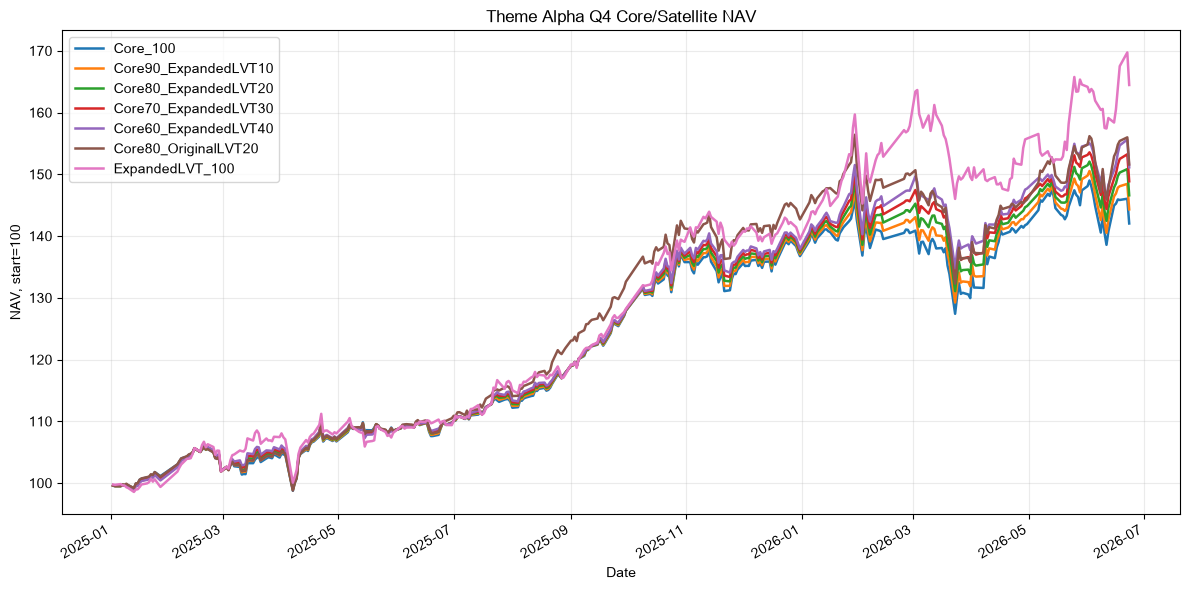

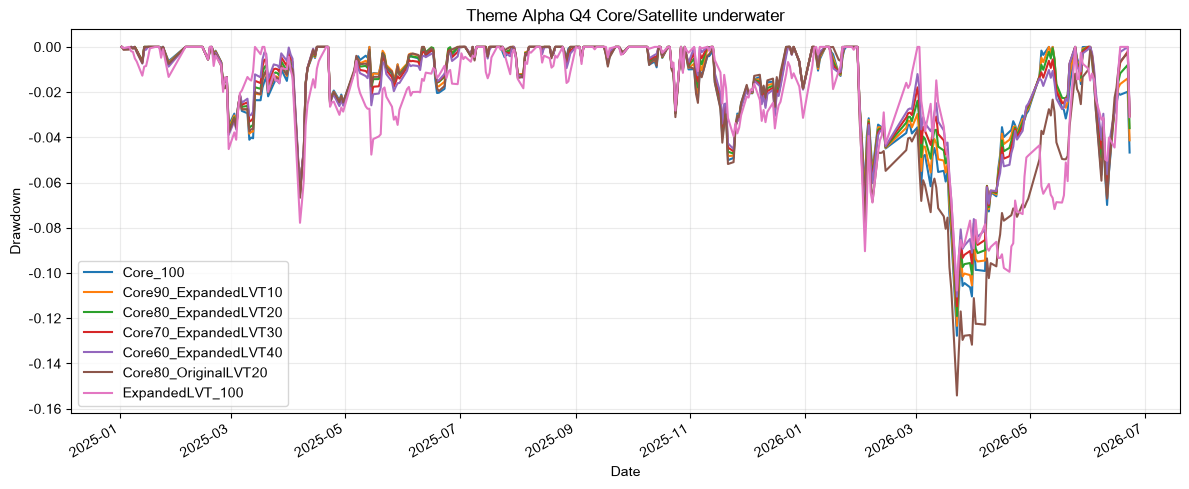

,best_return_2025_to_date,best_sharpe_2025_to_date,best_calmar_2025_to_date,best_underwater_quality,core_return,core80_expanded20_return,core70_expanded30_return,expanded100_return
0,OriginalLVT_100,OriginalLVT_100,ExpandedLVT_100,Core60_ExpandedLVT40,0.4204,0.466,0.4887,0.6447


In [7]:
main_names = ["Core_100", "Core90_ExpandedLVT10", "Core80_ExpandedLVT20", "Core70_ExpandedLVT30", "Core60_ExpandedLVT40", "Core80_OriginalLVT20", "ExpandedLVT_100"]
nav_main = nav_tables["2025_to_date"][main_names]
underwater_main = nav_main.apply(lambda s: s / s.cummax() - 1.0)

fig, ax = plt.subplots(figsize=(12, 6))
nav_main.plot(ax=ax, linewidth=1.8)
ax.set_title("Theme Alpha Q4 Core/Satellite NAV")
ax.set_ylabel("NAV, start=100")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "nav_core_satellite_2025_to_date.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
underwater_main.plot(ax=ax, linewidth=1.5)
ax.set_title("Theme Alpha Q4 Core/Satellite underwater")
ax.set_ylabel("Drawdown")
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "underwater_core_satellite_2025_to_date.png", dpi=160, bbox_inches="tight")
plt.show()

research_summary = pd.DataFrame([{
    "best_return_2025_to_date": summary_tables["2025_to_date"]["累计收益"].idxmax(),
    "best_sharpe_2025_to_date": summary_tables["2025_to_date"]["夏普"].idxmax(),
    "best_calmar_2025_to_date": summary_tables["2025_to_date"]["卡玛"].idxmax(),
    "best_underwater_quality": underwater_tables["2025_to_date"]["平均水下"].idxmax(),
    "core_return": summary_tables["2025_to_date"].loc["Core_100", "累计收益"],
    "core80_expanded20_return": summary_tables["2025_to_date"].loc["Core80_ExpandedLVT20", "累计收益"],
    "core70_expanded30_return": summary_tables["2025_to_date"].loc["Core70_ExpandedLVT30", "累计收益"],
    "expanded100_return": summary_tables["2025_to_date"].loc["ExpandedLVT_100", "累计收益"],
}])
research_summary.to_csv(OUTPUT_DIR / "research_summary.csv", index=False, encoding="utf-8-sig")
display(research_summary.round(4))
